# Notebook 1 - Audit qualité, nettoyage et exploration des données

**Objectif :** vérifier la qualité des trois tables, les nettoyer, puis les explorer pour justifier les choix des modèles.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110

ent = pd.read_parquet("data/entreprises.parquet")
trv = pd.read_parquet("data/travailleurs.parquet")
sin = pd.read_parquet("data/sinistres.parquet")

print("entreprises :", ent.shape)
print("travailleurs:", trv.shape)
print("sinistres   :", sin.shape)

entreprises : (337137, 6)
travailleurs: (1048001, 12)
sinistres   : (321127, 28)


In [2]:
sin.head(3)

,SINISTRE_ID,TRAVAILLEUR_ID,ENTREPRISE_ID,ANNEE_ACCIDENT,MOIS_ACCIDENT,PLAGE_HORAIRE,CLASSE_AGE,CLASSE_ANCIENNETE,CLASSE_ARRET,CLASSE_DELAI_DECLARATION,...,TYPE_SINISTRE,MORT_APRES_AT,RECHUTE,QUALIFICATION_EVENEMENT,CLASSE_MONTANT_FRAIS_MEDICAUX,CLASSE_MONTANT_FRAIS_PHARMACEUTIQUES,CLASSE_MONTANT_IJ_AT,CLASSE_MONTANT_RENTE_AT,CLASSE_MONTANT_RENTE_SURVIVANT,CLASSE_COUT_SIN_HORS_CAP_DECES
0,SIN_6DE120DB716C2B9BB536E0D41EFF25EA,TRV_38A2068E18CAAF87052DB1E277B82D4E,ENT_E41FD2868516BF54A769543E3B4650D4,1996.0,10.0,NaN,18-25,4-15,NaN,0,...,1,NON,NON,ACCIDENT_DU_TRAVAIL,0,0,0,0,0,0
1,SIN_6507F19FE4A12013514F9F362D6AA29F,TRV_8172116A050CCDD5585349ED5B9F4293,ENT_E41FD2868516BF54A769543E3B4650D4,1998.0,7.0,NaN,18-25,4-15,NaN,4-15,...,1,NON,NON,ACCIDENT_DU_TRAVAIL,0,0,0,0,0,0
2,SIN_E537C9E1F3DEE7699BB4C78FA24DF8F8,TRV_E7C06ED5CA094659AFDD4FB7488B0F46,ENT_E41FD2868516BF54A769543E3B4650D4,2001.0,8.0,NaN,36-45,4-15,NaN,0,...,1,NON,NON,ACCIDENT_DU_TRAVAIL,0,0,0,0,0,0


## 1. Audit qualité

### 1.1 Doublons

In [3]:
print("Sinistres : lignes en double         :", sin.duplicated().sum())
print("Travailleurs : identifiants en double :", trv["TRAVAILLEUR_ID"].duplicated().sum())
print("Entreprises : couples (id, année) en double :", ent.duplicated(["ENTREPRISE_ID", "ANNEE"]).sum())

Sinistres : lignes en double         : 65039


Travailleurs : identifiants en double : 6260
Entreprises : couples (id, année) en double : 0


### 1.2 Dates aberrantes

In [4]:
print("Années d'accident les plus anciennes :")
print(sin["ANNEE_ACCIDENT"].value_counts().sort_index().head(5))

Années d'accident les plus anciennes :
ANNEE_ACCIDENT
1899.0    58
1911.0     1
1924.0     1
1940.0     1
1944.0     1
Name: count, dtype: int64


### 1.3 Complétude de l'extraction des travailleurs

Le notebook 0 a vérifié que le nombre de lignes lues correspond **exactement** au nombre déclaré dans chaque fichier Excel (337 137 entreprises, 1 048 001 travailleurs, 321 127 sinistres) : aucune ligne n'a été perdue à la lecture. L'extraction transmise par la CNPS est donc traitée comme **complète**.

On vérifie simplement la répartition de la cible `STATUT_AT`, qui servira au modèle micro (notebook 4).

In [5]:
repartition = trv["STATUT_AT"].value_counts()
print(repartition)
print()
print("Nombre total d'assurés :", len(trv))
print("Part d'assurés avec accident :", round((trv["STATUT_AT"] == "AVEC_AT").mean() * 100, 1), "%")

STATUT_AT
SANS_AT    999431
AVEC_AT     48570
Name: count, dtype: int64

Nombre total d'assurés : 1048001
Part d'assurés avec accident : 4.6 %


**Ce que l'audit révèle :**

* **65 039 sinistres sont en double** (20 % de la table !). Sans nettoyage, tous les comptages seraient surestimés d'un quart.
* **58 sinistres sont datés de 1899** : c'est une date par défaut du logiciel, pas un vrai accident.
* **6 260 assurés apparaissent plusieurs fois** (assuré ayant travaillé dans plusieurs entreprises, ou ayant eu plusieurs accidents).
* Environ **4,3 % des assurés** ont eu un accident : la cible du modèle micro sera donc **très déséquilibrée** (cf. section 3.5).

### 1.4 Valeurs manquantes

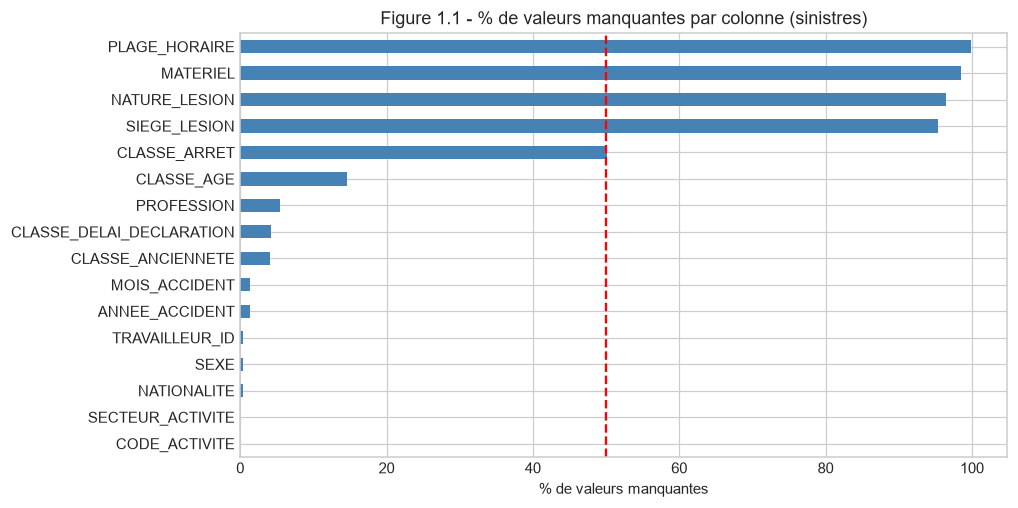

In [6]:
manquants = sin.isna().mean().sort_values() * 100
manquants = manquants[manquants > 0]

manquants.plot(kind="barh", figsize=(9, 5), color="steelblue")
plt.axvline(50, color="red", linestyle="--")
plt.title("Figure 1.1 - % de valeurs manquantes par colonne (sinistres)")
plt.xlabel("% de valeurs manquantes")
plt.show()

**Commentaire - Figure 1.1 :** quatre colonnes sont **presque vides** (plus de 95 % de valeurs manquantes) : `PLAGE_HORAIRE`, `MATERIEL`, `NATURE_LESION`, `SIEGE_LESION`. On ne peut pas les exploiter : elles sont supprimées. L'analyse « par plage horaire » prévue au départ est donc impossible avec ces données. `CLASSE_ARRET` est remplie pour un sinistre sur deux : on l'utilise avec prudence. Les autres colonnes sont bien remplies.

## 2. Nettoyage

Les règles découlent de l'audit :
1. **sinistres** : supprimer les doublons ; garder un seul enregistrement par `SINISTRE_ID` ; supprimer les années fictives (avant 1960) ; supprimer les 4 colonnes presque vides.
2. **travailleurs** : un assuré présent deux fois n'est gardé qu'une fois, de préférence sur sa ligne `AVEC_AT`.
3. **sexe** : seules les valeurs M et F sont conservées, les autres deviennent manquantes.
4. **entreprises** : l'année d'immatriculation 1900 est une valeur par défaut ; elle devient manquante.

In [7]:
# --- Sinistres
sin = sin.drop_duplicates()
sin = sin.drop_duplicates(subset="SINISTRE_ID")
sin = sin.drop(columns=["PLAGE_HORAIRE", "MATERIEL", "NATURE_LESION", "SIEGE_LESION"])
sin.loc[sin["ANNEE_ACCIDENT"] < 1960, "ANNEE_ACCIDENT"] = np.nan
sin.loc[~sin["SEXE"].isin(["M", "F"]), "SEXE"] = np.nan

# --- Travailleurs : les lignes AVEC_AT passent en premier, puis on garde la première ligne de chaque assuré
trv = trv.sort_values("STATUT_AT")          # "AVEC_AT" < "SANS_AT" dans l'ordre alphabétique
trv = trv.drop_duplicates(subset="TRAVAILLEUR_ID", keep="first")
trv.loc[~trv["SEXE"].isin(["M", "F"]), "SEXE"] = np.nan

# --- Entreprises
ent.loc[ent["DATE_IMMATRICULATION_ANNEE"] <= 1900, "DATE_IMMATRICULATION_ANNEE"] = np.nan

print("sinistres après nettoyage   :", len(sin))
print("travailleurs après nettoyage:", len(trv))

sinistres après nettoyage   : 255350
travailleurs après nettoyage: 1041741


On enregistre les tables propres.

In [8]:
sin.to_parquet("data/sinistres_propre.parquet", index=False)
trv.to_parquet("data/travailleurs_propre.parquet", index=False)
ent.to_parquet("data/entreprises_propre.parquet", index=False)

**Bilan du nettoyage :** il reste **255 350 sinistres uniques** (au lieu de 321 127) et **1 041 741 assurés uniques**. Ces tables propres seront utilisé pour la suite.

## 3. Exploration

### 3.1 Évolution du nombre de sinistres par année

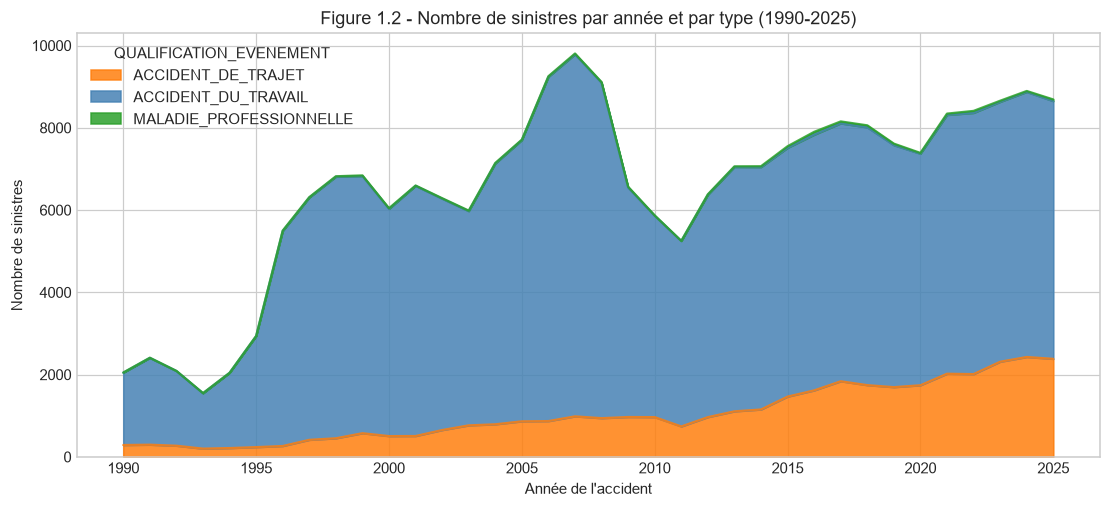

QUALIFICATION_EVENEMENT,ACCIDENT_DE_TRAJET,ACCIDENT_DU_TRAVAIL,MALADIE_PROFESSIONNELLE
ANNEE_ACCIDENT,,,
2018.0,1743,6267,49
2019.0,1694,5883,37
2020.0,1740,5629,19
2021.0,2020,6291,33
2022.0,2011,6350,49
2023.0,2312,6317,28
2024.0,2427,6444,23
2025.0,2382,6266,40


In [9]:
par_annee = pd.crosstab(sin["ANNEE_ACCIDENT"], sin["QUALIFICATION_EVENEMENT"])
par_annee = par_annee.loc[1990:2025]        # on s'arrête à 2025 : 2026 est incomplète (cf. ci-dessous)

par_annee.plot(kind="area", stacked=True, figsize=(12, 5), color=["tab:orange", "steelblue", "tab:green"], alpha=0.85)
plt.title("Figure 1.2 - Nombre de sinistres par année et par type (1990-2025)")
plt.xlabel("Année de l'accident")
plt.ylabel("Nombre de sinistres")
plt.show()

par_annee.tail(8)

**Commentaire - Figure 1.2 :**

* Le nombre de sinistres **augmente fortement jusqu'en 2007** (~9 800), puis **chute entre 2009 et 2011**, ce qui correspond à la période de crise politique (moins d'activité, donc moins de déclarations). Depuis 2012, il **remonte régulièrement** jusqu'à ~8 900 en 2024.
* Les **accidents de trajet** (en orange) prennent de plus en plus de place : environ 10 % des sinistres dans les années 2000, plus de 25 % aujourd'hui (2 427 en 2024). On **teste cette tendance** à la section 4 (hypothèse H4).
* Les **maladies professionnelles** sont presque invisibles (20 à 50 par an), ce qui indique une **sous-déclaration**.

> **Choix de méthode :** l'année **2026 est incomplète** (extraction arrêtée en cours d'année, déclarations tardives). Plutôt que de garder des mois partiels qui fausseraient les comptages et les tendances, **toute l'analyse exploratoire et tous les modèles s'arrêtent au 31 décembre 2025**. On prévoit ensuite l'année 2026 *entière* (notebook 2), ce qui respecte l'information métier et évite de mélanger du réel partiel avec des prévisions.

### 3.2 Les secteurs les plus touchés (2021–2025)

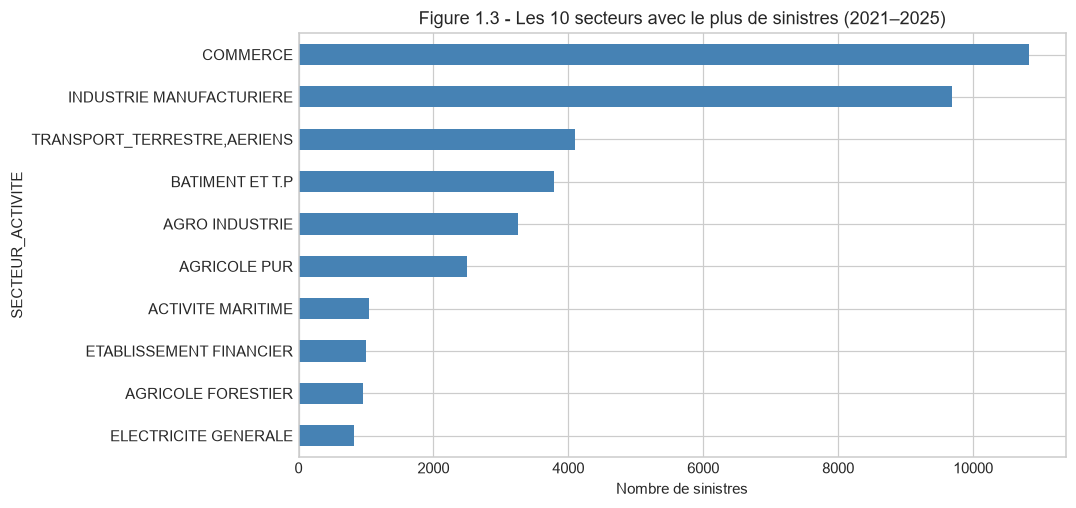

Part des 10 premiers secteurs : 88.3 %


In [10]:
recents = sin[(sin["ANNEE_ACCIDENT"] >= 2021) & (sin["ANNEE_ACCIDENT"] <= 2025)]
top10 = recents["SECTEUR_ACTIVITE"].value_counts().head(10)

top10.sort_values().plot(kind="barh", figsize=(9, 5), color="steelblue")
plt.title("Figure 1.3 - Les 10 secteurs avec le plus de sinistres (2021–2025)")
plt.xlabel("Nombre de sinistres")
plt.show()

print("Part des 10 premiers secteurs :", round(top10.sum() / len(recents) * 100, 1), "%")

**Commentaire - Figure 1.3 :** les accidents sont **concentrés dans peu de secteurs**. Le commerce et l'industrie manufacturière représentent à eux deux près de la moitié des sinistres, et les 10 premiers secteurs en représentent 88 %. Le transport et le BTP suivent. La prévention doit donc **cibler ces secteurs en priorité**.

⚠️ Il s'agit de **nombres** d'accidents, pas de **taux** : un secteur avec beaucoup de salariés a naturellement plus d'accidents. Pour calculer un taux, il faudrait connaître l'effectif de chaque secteur. La section 4 montre comment **tester statistiquement** ce que l'on peut dire malgré cette limite.

### 3.3 Âge des victimes

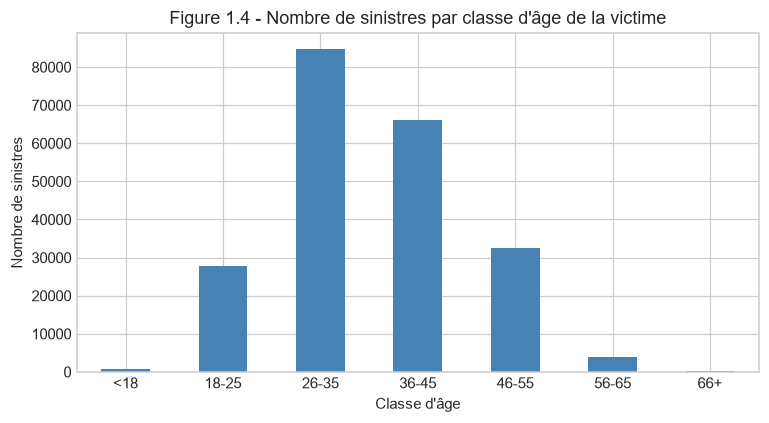

In [11]:
ordre_age = ["<18", "18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
sin["CLASSE_AGE"].value_counts().reindex(ordre_age).plot(kind="bar", figsize=(8, 4), color="steelblue", rot=0)
plt.title("Figure 1.4 - Nombre de sinistres par classe d'âge de la victime")
plt.xlabel("Classe d'âge")
plt.ylabel("Nombre de sinistres")
plt.show()

**Commentaire - Figure 1.4 :** la majorité des victimes ont **entre 26 et 45 ans**. Les moins de 18 ans et les plus de 56 ans sont peu nombreux. Cela reflète surtout la **pyramide des âges des salariés** : c'est la tranche la plus nombreuse au travail. La Figure 1.7 montre si ces âges ont vraiment un risque plus élevé.

### 3.4 Coût des sinistres selon leur type

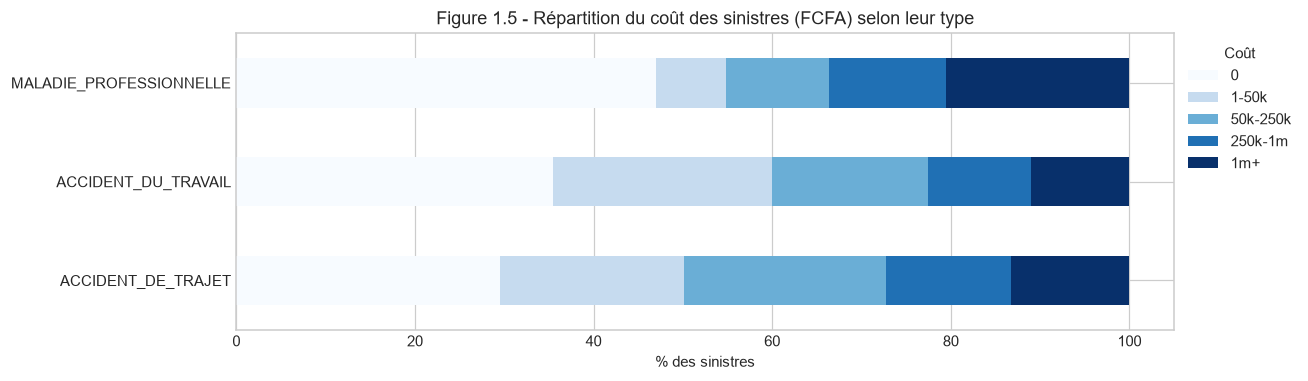

Taux de décès (%) :
QUALIFICATION_EVENEMENT
ACCIDENT_DE_TRAJET         0.36
ACCIDENT_DU_TRAVAIL        0.14
MALADIE_PROFESSIONNELLE    0.13
Name: OUI, dtype: float64


In [12]:
ordre_cout = ["0", "1-50k", "50k-250k", "250k-1m", "1m+"]
cout = pd.crosstab(sin["QUALIFICATION_EVENEMENT"], sin["CLASSE_COUT_SIN_HORS_CAP_DECES"], normalize="index") * 100
cout = cout[ordre_cout]

cout.plot(kind="barh", stacked=True, figsize=(11, 3.5), colormap="Blues")
plt.title("Figure 1.5 - Répartition du coût des sinistres (FCFA) selon leur type")
plt.xlabel("% des sinistres")
plt.ylabel("")
plt.legend(title="Coût", bbox_to_anchor=(1, 1))
plt.show()

print("Taux de décès (%) :")
print((pd.crosstab(sin["QUALIFICATION_EVENEMENT"], sin["MORT_APRES_AT"], normalize="index")["OUI"] * 100).round(2))

**Commentaire - Figure 1.5 :**

* Les **accidents de trajet coûtent plus cher** que les accidents du travail : une plus grande part dépasse 250 000 FCFA.
* Ils sont aussi **plus mortels** : 0,36 % de décès, soit **2,6 fois plus** que les accidents du travail (0,14 %).
* Les **maladies professionnelles** ont beaucoup de dossiers à coût nul (dossiers en cours ou rejetés), mais aussi une part importante de dossiers à plus de 1 million de FCFA.

➡️ La **prévention du risque routier** (trajets domicile-travail) est un levier important, à la fois pour sauver des vies et pour réduire les coûts.

### 3.5 La cible du modèle micro : `STATUT_AT`

STATUT_AT
SANS_AT    997187
AVEC_AT     44554
Name: count, dtype: int64

% d'assurés avec accident : 4.3 %


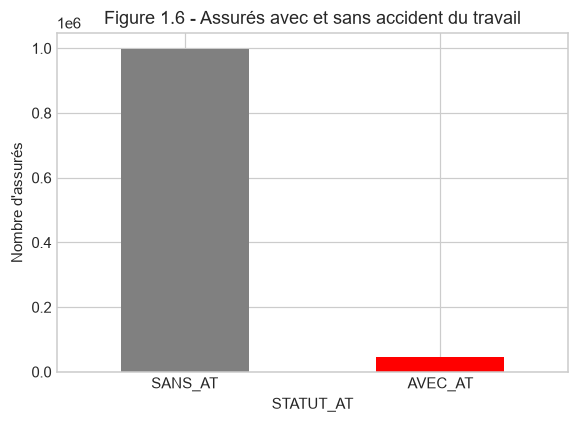

In [13]:
comptage = trv["STATUT_AT"].value_counts()
print(comptage)
print()
print("% d'assurés avec accident :", round(comptage["AVEC_AT"] / comptage.sum() * 100, 1), "%")

comptage.plot(kind="bar", figsize=(6, 4), color=["grey", "red"], rot=0)
plt.title("Figure 1.6 - Assurés avec et sans accident du travail")
plt.ylabel("Nombre d'assurés")
plt.show()

**Commentaire - Figure 1.6 :** seulement **4,3 % des assurés** ont eu un accident. Les classes sont donc **très déséquilibrées**. Un modèle qui répondrait toujours « pas d'accident » aurait 95,7 % de bonnes réponses, mais ne détecterait personne !


### 3.6 Taux d'accident selon le profil de l'assuré

Pour chaque modalité, on calcule le **% d'assurés ayant eu un accident**. Les valeurs manquantes sont regroupées dans une modalité « NON RENSEIGNE ».

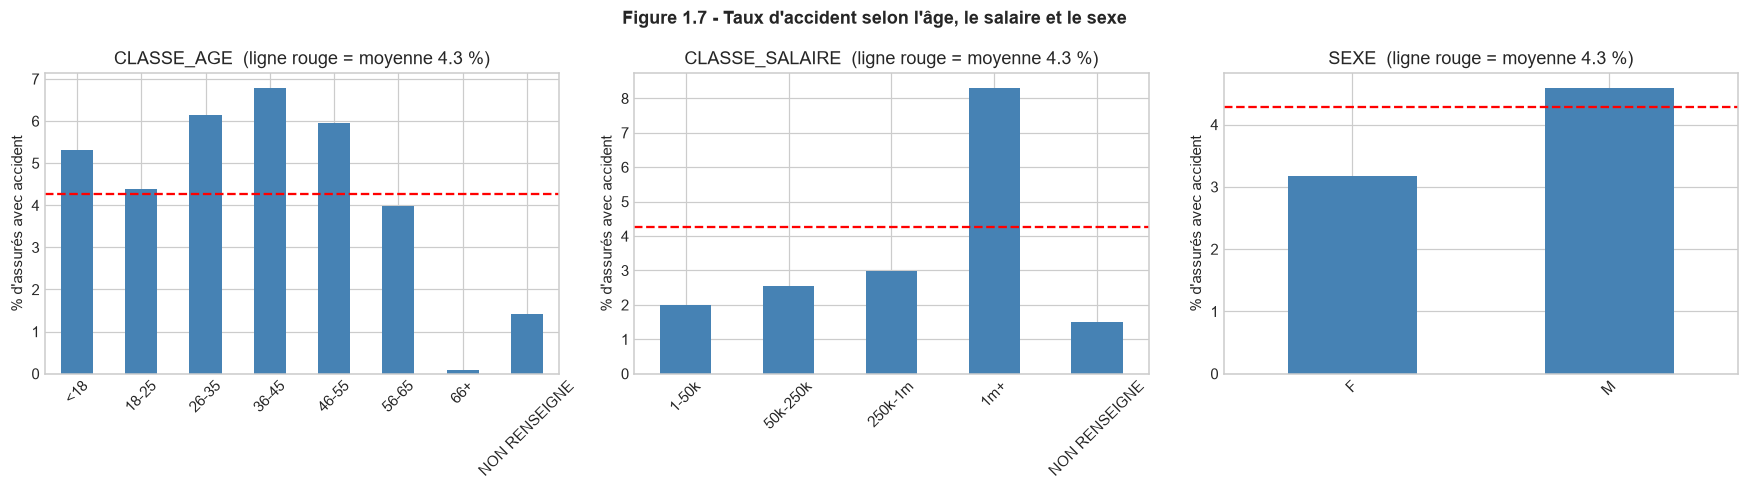

In [14]:
trv["accident"] = (trv["STATUT_AT"] == "AVEC_AT").astype(int)
taux_moyen = trv["accident"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

variables = {
    "CLASSE_AGE": ["<18", "18-25", "26-35", "36-45", "46-55", "56-65", "66+", "NON RENSEIGNE"],
    "CLASSE_SALAIRE": ["1-50k", "50k-250k", "250k-1m", "1m+", "NON RENSEIGNE"],
    "SEXE": ["F", "M"],
}
for ax, (col, ordre) in zip(axes, variables.items()):
    taux = trv.groupby(trv[col].fillna("NON RENSEIGNE"))["accident"].mean() * 100
    taux.reindex(ordre).plot(kind="bar", ax=ax, color="steelblue", rot=45)
    ax.axhline(taux_moyen, color="red", linestyle="--")
    ax.set_title(f"{col}  (ligne rouge = moyenne {taux_moyen:.1f} %)")
    ax.set_ylabel("% d'assurés avec accident")
    ax.set_xlabel("")

plt.suptitle("Figure 1.7 - Taux d'accident selon l'âge, le salaire et le sexe", fontweight="bold")
plt.tight_layout()
plt.show()

**Commentaire - Figure 1.7 :**

* **Âge :** le risque est le plus élevé chez les **36–45 ans (6,8 %)** et très faible chez les 66 ans et plus (0,1 %). Ces derniers sont sans doute en grande partie des retraités encore présents dans le registre.
* **Salaire :** les assurés de la classe **« 1m+ »** ont un taux de **8,3 %**, près de trois fois plus que les autres. Une explication probable : un salaire cumulé élevé correspond à une présence plus longue dans l'entreprise, donc à une exposition plus longue au risque.
* **Sexe :** les hommes ont plus d'accidents (4,6 % contre 3,2 %), car ils occupent plus souvent des métiers physiques.
* ⚠️ **« NON RENSEIGNE » :** quand l'âge ou le salaire n'est pas renseigné, le taux d'accident est très faible (~1,5 %). Explication probable : le dossier d'un accidenté est **complété** lors du traitement de l'accident. Le fait qu'une information soit remplie dépend donc **en partie de l'accident lui-même** : c'est un **biais de saisie**.

### 3.7 Attention à la fuite d'information : la variable `NOMBRE_ATM`

In [15]:
pd.crosstab(trv["NOMBRE_ATM"], trv["STATUT_AT"])

STATUT_AT,AVEC_AT,SANS_AT
NOMBRE_ATM,,
0,0,997187
1,43691,0
2,835,0
3,27,0
4,1,0


In [16]:
print("Les colonnes suivantes ne sont remplies QUE pour les accidentés :")
print(trv.groupby("STATUT_AT")[["ANNEE_ACCIDENT", "CLASSE_ANCIENNETE_AVANT_AT"]].count())

Les colonnes suivantes ne sont remplies QUE pour les accidentés :
           ANNEE_ACCIDENT  CLASSE_ANCIENNETE_AVANT_AT
STATUT_AT                                            
AVEC_AT             44554                       44495
SANS_AT                 0                           0


**Commentaire - point très important pour la soutenance :**

* `NOMBRE_ATM = 0` pour **tous** les assurés `SANS_AT`, et `NOMBRE_ATM ≥ 1` pour **tous** les assurés `AVEC_AT`. Cette variable **contient directement la réponse** : c'est une **fuite d'information** (*data leakage*).
* Si on l'utilisait dans le modèle micro, il obtiendrait un score quasi parfait… mais **totalement inutile en pratique** : pour connaître `NOMBRE_ATM`, il faut déjà savoir que la personne a eu un accident.
* De même, `ANNEE_ACCIDENT` et `CLASSE_ANCIENNETE_AVANT_AT` ne sont remplies **que** pour les accidentés.

## 4. Analyses statistiques : tests d'hypothèses

Les graphiques de la section 3 **suggèrent** des différences, mais une lecture visuelle peut tromper : un écart peut n'être qu'un effet du hasard de l'échantillon. On confirme donc chaque observation importante par un **test statistique**, avec une démarche explicite :

* **H₀** (hypothèse nulle) : « il n'y a pas d'effet / pas de lien » ;
* **H₁** (hypothèse alternative) : « il y a un effet » ;
* on rejette H₀ si la **p-value** est inférieure au seuil **α = 0,05**.

⚠️ Avec plus de 250 000 sinistres et 1 million d'assurés, **presque tout test est « significatif »**. On regarde donc aussi la **taille de l'effet** (V de Cramér : < 0,1 faible, 0,1–0,3 modéré ; ou le **risque relatif**), qui dit si l'effet est *important*, et pas seulement *réel*.

In [17]:
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

def v_cramer(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

sin_rec = sin[(sin["ANNEE_ACCIDENT"] >= 2021) & (sin["ANNEE_ACCIDENT"] <= 2025)].copy()

### 4.1 Hypothèse H1 - Le *profil* des accidents dépend du secteur

Le commerce affiche le plus grand **nombre** de sinistres (Figure 1.3), mais sans les effectifs par secteur on ne peut pas tester un *taux*. On teste donc une question qui, elle, ne dépend pas des effectifs : **la composition des accidents (travail / trajet / maladie pro) est-elle la même dans tous les secteurs ?** Si elle diffère, cela justifie une prévention adaptée secteur par secteur.

* **H₀** : le type d'accident est **indépendant** du secteur.
* **H₁** : le type d'accident **dépend** du secteur.
* **Test** : χ² d'indépendance (tableau secteur × type), sur les 6 principaux secteurs (2021–2025).

In [18]:
top6 = sin_rec["SECTEUR_ACTIVITE"].value_counts().head(6).index
st = sin_rec[sin_rec["SECTEUR_ACTIVITE"].isin(top6)]
table_h1 = pd.crosstab(st["SECTEUR_ACTIVITE"], st["QUALIFICATION_EVENEMENT"])

chi2, p, dof, _ = stats.chi2_contingency(table_h1)
print(f"chi2 = {chi2:.0f}   dof = {dof}   p-value = {p:.2e}   V de Cramer = {v_cramer(table_h1):.3f}")
print()
# part d'accidents de trajet par secteur, pour interpréter
part_trajet = (table_h1["ACCIDENT_DE_TRAJET"] / table_h1.sum(axis=1) * 100).round(1).sort_values(ascending=False)
print("Part d'accidents de TRAJET par secteur (%) :")
print(part_trajet)

chi2 = 903   dof = 10   p-value = 1.18e-187   V de Cramer = 0.115

Part d'accidents de TRAJET par secteur (%) :
SECTEUR_ACTIVITE
COMMERCE                       32.9
TRANSPORT_TERRESTRE,AERIENS    30.0
INDUSTRIE MANUFACTURIERE       20.7
AGRICOLE PUR                   18.2
BATIMENT ET T.P                18.1
AGRO INDUSTRIE                 13.9
dtype: float64


**Résultat H1 :** p-value ≈ 10⁻¹⁸⁷, très inférieure à 0,05 → **on rejette H₀**. Le profil des accidents **dépend bien du secteur** (V de Cramér ≈ 0,12, effet modéré). Concrètement, la part d'accidents de **trajet** varie fortement : élevée dans le **commerce** et le **transport** (~33 %), bien plus faible dans le **BTP** et l'**agricole** (~15 %), où le risque est surtout *sur le lieu de travail*.

➡️ Une prévention « taille unique » serait inadaptée : chaque secteur a sa signature de risque. Cela **justifie aussi un modèle de prévision par secteur** (notebook 2).

### 4.2 Hypothèse H2 - Dans le commerce, les métiers de *surveillance* ont plus d'accidents de trajet que les métiers de *manutention*

On descend au niveau du **métier**, comme demandé. Dans le secteur **commerce**, on oppose deux familles de professions aux caractéristiques opposées :

* **Surveillance** (agent de sécurité, vigile, surveillant) : poste souvent **statique**, peu de manipulation de charges ou de machines, mais des **trajets longs et à des horaires décalés** (nuit, très tôt) → on suppose que leurs accidents sont surtout des accidents **de trajet** (risque routier).
* **Manutention** (manutentionnaire, ouvrier, manœuvre, cariste, magasinier) : travail **physique sur site** (port de charges, engins) → on suppose surtout des accidents **sur le lieu de travail**.

* **H₀** : la part d'accidents de trajet est **la même** dans les deux familles.
* **H₁** : elle est **plus élevée** chez les métiers de surveillance.
* **Test** : z-test de comparaison de deux proportions.

In [19]:
commerce = sin_rec[sin_rec["SECTEUR_ACTIVITE"] == "COMMERCE"].copy()
commerce["trajet"] = (commerce["QUALIFICATION_EVENEMENT"] == "ACCIDENT_DE_TRAJET").astype(int)

surveillance = {"AGENT DE SECURITE", "AGENT DE SÉCURITÉ", "VIGILE", "SURVEILLANT"}
manutention = {"MANUTENTIONNAIRE", "OUVRIER", "MANOEUVRE", "CARISTE", "MAGASINIER"}

g_surv = commerce[commerce["PROFESSION"].isin(surveillance)]["trajet"]
g_manu = commerce[commerce["PROFESSION"].isin(manutention)]["trajet"]

z, p = proportions_ztest([g_surv.sum(), g_manu.sum()], [len(g_surv), len(g_manu)], alternative="larger")
print(f"Surveillance : {g_surv.mean()*100:.1f} % de trajet  (n = {len(g_surv)})")
print(f"Manutention  : {g_manu.mean()*100:.1f} % de trajet  (n = {len(g_manu)})")
print(f"z = {z:.1f}   p-value (test unilatéral) = {p:.2e}   risque relatif = {g_surv.mean()/g_manu.mean():.2f}")

Surveillance : 46.7 % de trajet  (n = 2145)
Manutention  : 21.0 % de trajet  (n = 1385)
z = 15.5   p-value (test unilatéral) = 3.73e-54   risque relatif = 2.22


**Résultat H2 :** 46,7 % de trajet chez les métiers de **surveillance** contre 21,0 % chez la **manutention** (z ≈ 15,5, p ≈ 10⁻⁵⁴) → **on rejette H₀**. L'hypothèse est **confirmée** : à secteur égal, les agents de sécurité / vigiles ont **2,2 fois plus** d'accidents de trajet que les manutentionnaires.

➡️ C'est exactement le genre de résultat exploitable : la **prévention du risque routier** (sensibilisation aux trajets, aménagement des horaires, transport) devrait **cibler en priorité les métiers de surveillance**, alors que la **sécurité sur site** (gestes et postures, engins) concerne davantage la manutention. La démarche a transformé une intuition en **recommandation chiffrée et testée**.

### 4.3 Hypothèse H3 - Les accidents de trajet sont plus souvent mortels

La Figure 1.5 suggère que les accidents de trajet sont plus graves. On le teste sur **tout l'historique** (les décès sont rares : il faut un grand effectif).

* **H₀** : le taux de décès est **identique** pour les accidents de trajet et de travail.
* **H₁** : il est **plus élevé** pour les accidents de trajet.
* **Test** : z-test de deux proportions.

In [20]:
deces = (sin["MORT_APRES_AT"] == "OUI").astype(int)
trajet = sin["QUALIFICATION_EVENEMENT"] == "ACCIDENT_DE_TRAJET"
travail = sin["QUALIFICATION_EVENEMENT"] == "ACCIDENT_DU_TRAVAIL"

d_trajet, d_travail = deces[trajet], deces[travail]
z, p = proportions_ztest([d_trajet.sum(), d_travail.sum()], [len(d_trajet), len(d_travail)], alternative="larger")
print(f"Trajet  : {d_trajet.mean()*100:.3f} % de deces  (n = {len(d_trajet):,})")
print(f"Travail : {d_travail.mean()*100:.3f} % de deces  (n = {len(d_travail):,})")
print(f"z = {z:.1f}   p-value = {p:.2e}   risque relatif = {d_trajet.mean()/d_travail.mean():.2f}")

Trajet  : 0.359 % de deces  (n = 39,553)
Travail : 0.140 % de deces  (n = 215,054)
z = 9.6   p-value = 5.06e-22   risque relatif = 2.56


**Résultat H3 :** 0,359 % de décès pour les trajets contre 0,140 % pour les accidents de travail (z ≈ 9,6, p ≈ 10⁻²¹) → **on rejette H₀**. Un accident de trajet est **2,6 fois plus souvent mortel**. Combiné à H1 (le trajet domine dans le commerce et le transport) et à H2 (surtout chez les métiers de surveillance), cela fait du **risque routier un levier de prévention prioritaire**.

### 4.4 Hypothèse H4 - Le sexe et l'âge sont liés au risque d'accident

La Figure 1.7 montre des écarts de taux d'accident selon le profil. On teste si ces liens sont réels **dans la population des assurés** (table travailleurs).

* **H₀** : le fait d'avoir eu un accident est **indépendant** du sexe (resp. de l'âge).
* **H₁** : il en **dépend**.
* **Test** : χ² d'indépendance + z-test hommes/femmes.

In [21]:
acc = (trv["STATUT_AT"] == "AVEC_AT").astype(int)

for col in ["SEXE", "CLASSE_AGE"]:
    table = pd.crosstab(trv[col], acc)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    print(f"{col:11s} : chi2 = {chi2:.0f}   p = {p:.2e}   V de Cramer = {v_cramer(table):.3f}")

h = trv[trv["SEXE"] == "M"]; f = trv[trv["SEXE"] == "F"]
ah = (h["STATUT_AT"] == "AVEC_AT"); af = (f["STATUT_AT"] == "AVEC_AT")
z, p = proportions_ztest([ah.sum(), af.sum()], [len(h), len(f)], alternative="larger")
print(f"\nHommes : {ah.mean()*100:.2f} %   Femmes : {af.mean()*100:.2f} %   z = {z:.1f}   p = {p:.2e}")

SEXE        : chi2 = 876   p = 1.49e-192   V de Cramer = 0.029


CLASSE_AGE  : chi2 = 4727   p = 0.00e+00   V de Cramer = 0.080



Hommes : 4.59 %   Femmes : 3.18 %   z = 29.6   p = 6.28e-193


**Résultat H4 :** on **rejette H₀** dans les deux cas (p ≪ 0,05) : le sexe et l'âge sont bien liés au risque d'accident enregistré (hommes 4,6 % contre femmes 3,2 %). **Mais** les tailles d'effet sont **faibles** (V de Cramér ≈ 0,03 pour le sexe, ≈ 0,08 pour l'âge) : aucune variable prise seule ne suffit à repérer les assurés à risque.

➡️ Cela **justifie un modèle multivarié** (notebook 4), qui combine toutes ces variables faibles en un score, plutôt qu'une simple règle sur une seule variable.

### Bilan des tests

| Hypothèse | Test | p-value | Taille d'effet | Décision |
|---|---|---|---|---|
| H1 – profil d'accident lié au secteur | χ² | ≈ 10⁻¹⁸⁷ | V ≈ 0,12 (modéré) | H₀ rejetée |
| H2 – surveillance > manutention (trajet, commerce) | z 2 prop. | ≈ 10⁻⁵⁴ | RR ≈ 2,2 | H₀ rejetée |
| H3 – trajet plus mortel | z 2 prop. | ≈ 10⁻²¹ | RR ≈ 2,6 | H₀ rejetée |
| H4 – sexe / âge liés à l'accident | χ² | ≪ 0,05 | V ≈ 0,03–0,08 (faible) | H₀ rejetée |

Ces tests **étayent scientifiquement** les choix de modélisation des notebooks suivants : prévention et prévision **par secteur** (H1), priorité au **risque routier** ciblé (H2, H3), et **modèle multivarié** pour les assurés (H4).

## 5. Synthèse

| Ce qu'on a trouvé | Ce qu'on en fait |
|---|---|
| 20 % de doublons, dates fictives, 4 colonnes vides | Tables nettoyées et enregistrées (`data/*_propre.parquet`) |
| Sinistralité en hausse depuis 2012, 2026 incomplète (année en cours) | Analyse et modèles **arrêtés à fin 2025** ; **Notebook 2** : prévision mensuelle et prévision de l'année 2026 entière |
| Accidents concentrés par secteur, profil de risque **différent selon le secteur** (test H1) | **Notebook 2** : un modèle de prévision **par secteur** |
| Risque routier : trajet plus fréquent chez la surveillance (H2) et 2,6× plus mortel (H3) | Prévention routière ciblée ; levier transversal des plans d'action |
| Cible micro rare (4,3 %), fuite via `NOMBRE_ATM`, variables faibles prises seules (H4) | **Notebook 4** : modèle **multivarié** sans fuite, classes pondérées, seuil adapté |